# 09 · Scientific Machine Learning: PINNs and Neural Operators

This notebook is a module of **Neural Networks 1002** and assumes [module 02 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/02-neural-network-backprop/) (backpropagation, which here becomes **automatic differentiation** of the network with respect to its *inputs*) and [module 03](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) (training well: Adam, learning-rate schedules, why a badly scaled loss is hard to optimise).

A simulation of a flow, a vibrating structure or a heat-conducting body is a program that solves an equation. That program is accurate, but it can be slow (hours on a cluster for one run), it needs the equation, the geometry and the initial state to be known exactly, and it must be run again for every new case. A neural network is the opposite: fast once trained, flexible, but hungry for data and with no idea of physics. **Scientific machine learning** (SciML) is the family of methods that combine the two. In this notebook you will build, in pure PyTorch and on a laptop CPU, with fixed seeds and with every claim measured:

1. a **classical numerical solver** (finite differences) for the heat equation, with its accuracy, convergence order and cost, because every neural method below must be compared with it;
2. a **physics-informed neural network** (PINN) for an ordinary differential equation (a damped oscillator), where the equation enters the loss through automatic differentiation, with the effect of the **loss weights** and of **hard constraints**, and a case with few noisy measurements where physics rescues an extrapolation;
3. a PINN for a **partial differential equation** (the 1D heat equation) with boundary and initial conditions, with the measured error against the exact solution and against the finite-difference solver, in accuracy and in seconds;
4. the **inverse problem**: identify the diffusion coefficient from noisy measurements, compared with classical least-squares fitting, as parameter error against noise level;
5. the **known failure modes** of PINNs, shown and measured: spectral bias (and the Fourier-feature remedy), loss imbalance (and adaptive weights), and stiff or long-horizon problems (and causal training);
6. **neural operators**, which learn the map from an initial condition to the solution instead of a single solution: a small **DeepONet** (deep operator network) and a small **Fourier neural operator** (FNO) for the viscous Burgers equation, with training data from our own solver, tested on new initial conditions, on a finer grid and against the solver's speed;
7. a **decision table** (solver, PINN, neural operator or hybrid) and an honest survey of the large scientific models (weather, proteins, materials).

**Contents**

1. Why scientific machine learning
2. The baseline: a classical solver
3. PINN from scratch: an ordinary differential equation
4. PINN for the heat equation
5. The inverse problem: identify a parameter from noisy data
6. When PINNs fail, and the remedies
7. Neural operators: learn the solution map
8. Which tool for which problem
9. Large scientific models: what is established
10. Key takeaways, exercises, references

| Builds on | What we reuse |
|---|---|
| [02 Neural network and backprop (1001)](https://neural-networks.academy.forwardforecasting.eu/02-neural-network-backprop/) | autograd: the same machinery that gives the gradient with respect to the weights gives the derivative of the output with respect to the input |
| [03 Training deep networks (1001)](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) | Adam, learning-rate decay, loss scaling and why several loss terms must be balanced |

New to PyTorch? The [Python 1001 course, section on AI frameworks](https://python.academy.forwardforecasting.eu/11-ai-frameworks/) introduces it. All data are generated in the notebook (no download), only NumPy, SciPy, matplotlib and PyTorch are used (all preinstalled on Google Colab), and the notebook uses two threads. **Time:** about 11 minutes end to end on a 2-thread run on our (shared) cluster; on a free Colab runtime with 2 vCPUs expect somewhat longer, we have not measured it. The L-BFGS stages and the convection runs of section 6.3 are the slowest cells. The physics here is deliberately generic and small (an oscillator, heat conduction in a rod, Burgers' equation for a one-dimensional fluid); the same ideas carry to larger problems, where, as the survey in section 9 shows, the open questions are mostly about scale and evidence.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/09_scientific_machine_learning.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). **Measured run time** in a clean 2-CPU environment like Colab's: about 9 minutes, with a peak memory of under 1 GB (model and data downloads were done on a fast connection). A free Colab CPU is usually slower than the machine used for the measurement, so allow more time; the timings printed in the saved outputs come from a multi-core machine.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'scipy': 'scipy',
    'torch': 'torch',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.linalg import solve_banded
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.interpolate import RegularGridInterpolator

import os
torch.set_num_threads(min(2, os.cpu_count() or 2))        # two threads: what a free Colab runtime offers
torch.manual_seed(0); np.random.seed(0); random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 100
T_START = time.time()

def mlp(sizes, act=nn.Tanh):
    # a plain multilayer perceptron with Xavier initialisation (the usual choice for tanh PINNs)
    layers = []
    for i in range(len(sizes) - 1):
        layers.append(nn.Linear(sizes[i], sizes[i + 1]))
        if i < len(sizes) - 2:
            layers.append(act())
    net = nn.Sequential(*layers)
    for m in net:
        if isinstance(m, nn.Linear):
            nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    return net

def d(y, x):
    # derivative of y with respect to x, kept differentiable so we can differentiate again
    return torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]

def rel_l2(pred, true):
    # relative L2 error: norm of the difference divided by the norm of the true solution
    return float(np.linalg.norm(np.asarray(pred) - np.asarray(true)) / np.linalg.norm(true))

## 1. Why scientific machine learning

Three situations push people from a plain solver or a plain network towards a mixture of both.

* **Expensive simulations.** A weather, combustion or crash simulation can take hours for one scenario. If you must evaluate thousands of scenarios (design optimisation, uncertainty quantification, real-time control), a fast **surrogate** that imitates the simulator is valuable. A network trained on simulator output is such a surrogate, and a **neural operator** (section 7) is the version that works for a whole family of inputs.
* **Sparse data, known physics.** You have a handful of noisy sensors but you know the governing law up to a few constants. A plain network fits the points and extrapolates nonsense; a model that is forced to obey the law needs far fewer points. This is the idea of the **PINN** (Raissi, Perdikaris and Karniadakis, 2019): put the equation into the loss.
* **Unknown parameters or missing terms.** The equation holds but a coefficient (a diffusivity, a damping ratio, a viscosity) is not known and must be inferred from measurements: an **inverse problem**.

There is also a warning to carry through the notebook. The classical solver is a very strong baseline: for a well-posed forward problem it is usually **more accurate and cheaper** than a PINN, and published claims of large speed-ups for neural PDE solvers have been found to rest on weak baselines (McGreivy and Hakim, 2024; Grossmann et al., 2024; both in the references). Neural methods earn their place where the solver is too slow to call many times, where data and physics must be combined, or where the problem is inverse; we measure each of these rather than assume it.

| Method | What it learns | Needs the equation? | Needs simulation data? | One trained model covers |
|---|---|---|---|---|
| classical solver | nothing (it computes) | yes | no | one case per run |
| PINN | one solution (or one parameter) | yes, in the loss | no, or a few measurements | one case |
| neural operator | the map from inputs to solutions | no | yes, many solver runs | a whole family of cases |
| hybrid | a correction or a missing term | partly | some | depends |

## 2. The baseline: a classical solver

Our first test problem is **heat conduction in a thin rod** of length 1 with its two ends held at temperature zero:

$$\frac{\partial u}{\partial t} = \nu\,\frac{\partial^2 u}{\partial x^2},\qquad u(0,t)=u(1,t)=0,\qquad u(x,0)=\sin(\pi x)+\tfrac12\sin(3\pi x),$$

where $u(x,t)$ is the temperature at position $x$ and time $t$, and $\nu$ (the Greek letter nu) is the **diffusion coefficient** (how fast heat spreads; we use $\nu=0.05$). The exact solution is known, because each sine decays at its own rate:

$$u(x,t)=e^{-\nu\pi^2 t}\sin(\pi x)+\tfrac12 e^{-9\nu\pi^2 t}\sin(3\pi x).$$

Having an exact answer lets us measure every method's error honestly. The **finite-difference method** replaces derivatives by differences on a grid of $n_x$ cells (cell width $\Delta x=1/n_x$) and $n_t$ time steps (step $\Delta t=1/n_t$). We code two classic schemes: **FTCS** (forward time, centred space), which is explicit and only stable when $r=\nu\Delta t/\Delta x^2\le 1/2$, and **Crank-Nicolson** (CN), which averages the old and new time level, is unconditionally stable and has second-order accuracy in both $\Delta x$ and $\Delta t$.

Crank-Nicolson, dt = dx, error at t = 1 (max over the grid)
   nx   max error  order  time (ms)
   10    3.08e-03             0.224
   20    7.26e-04   2.08      0.398
   40    1.79e-04   2.02      0.796
   80    4.48e-05   2.00      1.635
  160    1.12e-05   2.00      3.583
  320    2.80e-06   2.00      8.774
FTCS nx=50 nt=50 r=2.50: max |u| at t=1 = 1.87e+31 (exact max 0.605)
FTCS nx=50 nt=500 r=0.25: max |u| at t=1 = 0.605 (exact max 0.605)
oscillator RK45 rtol=0.001: relative L2 error 1.5e-03, 1.30 ms
oscillator RK45 rtol=1e-06: relative L2 error 8.9e-07, 4.70 ms


oscillator RK45 rtol=1e-09: relative L2 error 8.0e-10, 17.19 ms


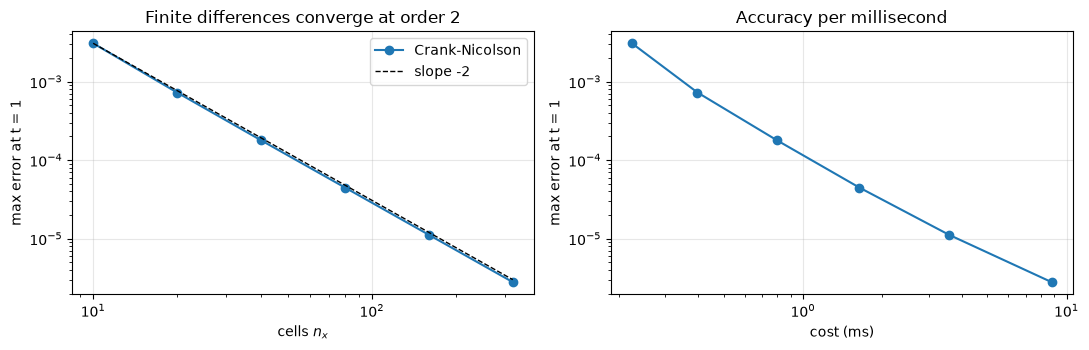

In [2]:
NU = 0.05                                    # diffusion coefficient of the heat equation

def u0_heat(x):
    return np.sin(np.pi * x) + 0.5 * np.sin(3 * np.pi * x)

def heat_exact(x, t, nu=NU):
    return (np.exp(-nu * np.pi**2 * t) * np.sin(np.pi * x)
            + 0.5 * np.exp(-9 * nu * np.pi**2 * t) * np.sin(3 * np.pi * x))

def heat_fd(nx, nt, nu=NU, T=1.0, scheme="cn", u0=u0_heat, keep=False):
    # finite differences for u_t = nu u_xx on [0,1], zero ends. Returns x, u(T) (and all time levels if keep)
    x = np.linspace(0, 1, nx + 1); dx = 1.0 / nx; dt = T / nt; r = nu * dt / dx**2
    u = u0(x).astype(float); hist = [u.copy()]
    if scheme == "cn":
        n = nx - 1
        ab = np.zeros((3, n)); ab[0, 1:] = -r / 2; ab[1, :] = 1 + r; ab[2, :-1] = -r / 2   # banded matrix of the implicit half
    for _ in range(nt):
        lap = u[2:] - 2 * u[1:-1] + u[:-2]
        if scheme == "ftcs":
            u[1:-1] = u[1:-1] + r * lap
        else:
            u[1:-1] = solve_banded((1, 1), ab, u[1:-1] + r / 2 * lap)
        if keep: hist.append(u.copy())
    return (x, u, np.array(hist)) if keep else (x, u)

def timed(f, reps=20):
    t0 = time.perf_counter()
    for _ in range(reps): out = f()
    return out, (time.perf_counter() - t0) / reps

rows = []
for nx in [10, 20, 40, 80, 160, 320]:
    (x, u), sec = timed(lambda: heat_fd(nx, nx, scheme="cn"))              # time step = cell width
    err = np.abs(u - heat_exact(x, 1.0)).max()
    rows.append((nx, err, sec))
print("Crank-Nicolson, dt = dx, error at t = 1 (max over the grid)")
print(f"{'nx':>5} {'max error':>11} {'order':>6} {'time (ms)':>10}")
for i, (nx, err, sec) in enumerate(rows):
    order = "" if i == 0 else f"{np.log2(rows[i-1][1] / err):.2f}"
    print(f"{nx:>5} {err:>11.2e} {order:>6} {sec*1e3:>10.3f}")

# explicit scheme: stable only if r <= 1/2
for nx, nt in [(50, 50), (50, 500)]:
    x, u = heat_fd(nx, nt, scheme="ftcs")
    r = NU * (1.0 / nt) / (1.0 / nx) ** 2
    print(f"FTCS nx={nx} nt={nt} r={r:.2f}: max |u| at t=1 = {np.abs(u).max():.3g} (exact max {np.abs(heat_exact(x, 1.0)).max():.3f})")

# the oscillator solved by a standard adaptive Runge-Kutta, for the next section
W0, ZETA = 2.0, 0.1                          # natural angular frequency and damping ratio
def osc_exact(t, w0=W0, zeta=ZETA):
    a = zeta * w0; wd = w0 * np.sqrt(1 - zeta**2)
    return np.exp(-a * t) * (np.cos(wd * t) + a / wd * np.sin(wd * t))
tt = np.linspace(0, 10, 500)
for rtol in [1e-3, 1e-6, 1e-9]:
    sol, sec = timed(lambda: solve_ivp(lambda t, y: [y[1], -2 * ZETA * W0 * y[1] - W0**2 * y[0]], (0, 10), [1.0, 0.0],
                                       t_eval=tt, rtol=rtol, atol=rtol * 1e-3, method="RK45"))
    print(f"oscillator RK45 rtol={rtol:g}: relative L2 error {rel_l2(sol.y[0], osc_exact(tt)):.1e}, {sec*1e3:.2f} ms")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
nxs = np.array([r_[0] for r_ in rows]); errs = np.array([r_[1] for r_ in rows]); secs = np.array([r_[2] for r_ in rows])
ax[0].loglog(nxs, errs, "o-", label="Crank-Nicolson"); ax[0].loglog(nxs, errs[0] * (nxs[0] / nxs) ** 2, "k--", lw=1, label="slope -2")
ax[0].set_xlabel("cells $n_x$"); ax[0].set_ylabel("max error at t = 1"); ax[0].legend(); ax[0].set_title("Finite differences converge at order 2")
ax[1].loglog(secs * 1e3, errs, "o-"); ax[1].set_xlabel("cost (ms)"); ax[1].set_ylabel("max error at t = 1"); ax[1].set_title("Accuracy per millisecond")
plt.tight_layout(); plt.show()

**Reading.** The two schemes behave as theory says. Crank-Nicolson shows an observed order of 2.00 (the error falls by four when the grid is refined by two), from 3e-3 with 10 cells to 2.8e-6 with 320 cells in 9 ms, and the explicit scheme is stable at $r=0.25$ and blows up (values of 1e31) at $r=2.5$. The adaptive Runge-Kutta solver reaches 9e-7 on the oscillator in under 5 ms. These are the numbers a neural method has to beat: a solver with an error of 1e-5 or 1e-6 in a few milliseconds, with a known convergence order and a stability condition. Keep them in mind in every table below. (Timings are wall-clock on a shared machine and vary by a few tens of percent.)

## 3. PINN from scratch: an ordinary differential equation

A **physics-informed neural network** represents the unknown solution by a network $x_\theta(t)$ (with weights $\theta$, the Greek letter theta) and trains it to make the *residual* of the equation small at many **collocation points** (points where we test the equation). We start with the simplest equation: a **damped oscillator**, a mass on a spring with friction,

$$\ddot x + 2\zeta\omega_0\,\dot x+\omega_0^2\,x = 0,\qquad x(0)=1,\ \dot x(0)=0,$$

where $x(t)$ is the displacement, $\dot x$ and $\ddot x$ its first and second derivative in time, $\omega_0$ the natural angular frequency ($\omega_0=2$) and $\zeta$ (zeta) the damping ratio ($\zeta=0.1$, lightly damped). The **residual** is the left-hand side evaluated on the network; **automatic differentiation** gives $\dot x_\theta$ and $\ddot x_\theta$ exactly, with no finite differences. The loss is

$$\mathcal L=\underbrace{\frac1{N_c}\sum_i\big(\ddot x_\theta(t_i)+2\zeta\omega_0\dot x_\theta(t_i)+\omega_0^2x_\theta(t_i)\big)^2}_{\text{physics residual}}+\lambda\,\underbrace{\big[(x_\theta(0)-1)^2+\dot x_\theta(0)^2\big]}_{\text{initial conditions}},$$

with $N_c=200$ collocation points on $[0,10]$ and a weight $\lambda$ (lambda) that decides how much the initial conditions count. Without them the network may learn the trivial solution $x\equiv0$, which also satisfies the equation. There is an alternative to the soft penalty: a **hard constraint**, writing $x_\theta(t)=1+t^2\,N_\theta(t)$, which satisfies $x(0)=1$ and $\dot x(0)=0$ for every network $N_\theta$ by construction.

Optimisation has two stages, the usual PINN recipe: 3,000 steps of **Adam**, then up to 500 iterations of **L-BFGS** (limited-memory Broyden-Fletcher-Goldfarb-Shanno, a quasi-Newton method that uses curvature and needs a fixed set of points, so it polishes what Adam found). We compare $\lambda\in\{0.01,1,100\}$ and the hard constraint over two seeds, and measure the relative L2 error against the exact solution on $[0,10]$. (Inside the network the time is rescaled to $t/10$, a standard way to keep the inputs of a tanh network in a good range.)

soft, lambda = 1     relative L2 error per seed: 4.21e-03, 1.25e-01   (7.7 s per run)


soft, lambda = 100   relative L2 error per seed: 4.61e-01, 4.23e-01   (7.3 s per run)


hard constraint      relative L2 error per seed: 2.43e-01, 1.43e-01   (7.2 s per run)


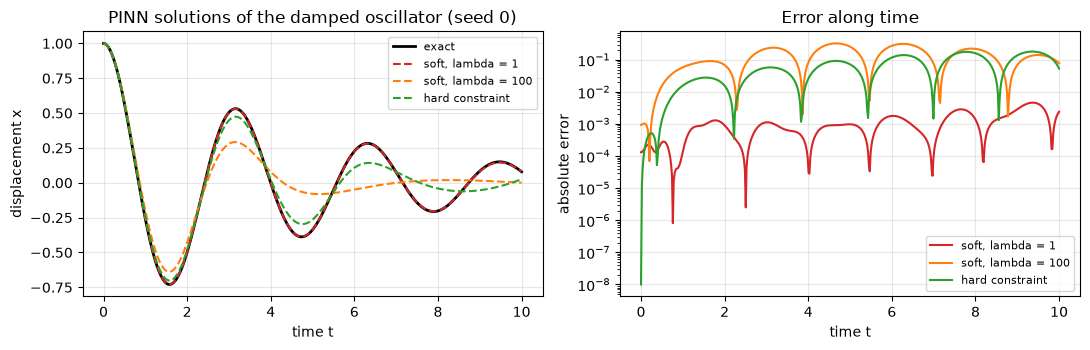

In [3]:
def train_osc(mode, seed, w_ic=1.0, steps=3000, obs=None, w_data=1.0):
    # mode: "soft" (penalty on the initial conditions), "hard" (constraint by construction),
    #       "data" (fit the observations only), "phys+data" (residual + observations, initial conditions NOT given)
    torch.manual_seed(seed)
    net = mlp([1, 32, 32, 32, 1])
    f = (lambda t: 1.0 + (t / 10) ** 2 * net(t / 10) * 10) if mode == "hard" else (lambda t: net(t / 10))   # time is rescaled to [0, 1] inside the network
    tc = torch.linspace(0, 10, 200).reshape(-1, 1).requires_grad_(True)
    t0 = torch.zeros(1, 1, requires_grad=True)
    if obs is not None:
        to = torch.tensor(obs[0], dtype=torch.float32).reshape(-1, 1); xo = torch.tensor(obs[1], dtype=torch.float32).reshape(-1, 1)
    def loss_fn():
        loss = 0.0
        if mode in ("soft", "hard", "phys+data"):
            x = f(tc); dx = d(x, tc); ddx = d(dx, tc)
            loss = ((ddx + 2 * ZETA * W0 * dx + W0**2 * x) ** 2).mean()          # physics residual
        if mode == "soft":
            x0 = f(t0); loss = loss + w_ic * ((x0 - 1) ** 2 + d(x0, t0) ** 2).sum()
        if mode in ("data", "phys+data"):
            loss = loss + w_data * ((f(to) - xo) ** 2).mean()
        return loss
    t_start = time.perf_counter()
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(1e-2) ** (1.0 / steps))
    for s in range(steps):                                                       # stage 1: Adam
        opt.zero_grad(); loss_fn().backward(); opt.step(); sched.step()
    lbfgs = torch.optim.LBFGS(net.parameters(), lr=1, max_iter=500, history_size=50, line_search_fn="strong_wolfe")
    def closure():                                                               # stage 2: L-BFGS polish, the usual PINN recipe
        lbfgs.zero_grad(); l = loss_fn(); l.backward(); return l
    lbfgs.step(closure)
    sec = time.perf_counter() - t_start
    with torch.no_grad():
        tt_ = torch.tensor(tt, dtype=torch.float32).reshape(-1, 1)
        pred = f(tt_).numpy().ravel()
    return pred, sec

tt = np.linspace(0, 10, 500)
xt = osc_exact(tt)
results_osc = {}
for name, kw in [("soft, lambda = 1", dict(mode="soft", w_ic=1.0)), ("soft, lambda = 100", dict(mode="soft", w_ic=100.0)),
                 ("hard constraint", dict(mode="hard"))]:
    errs, secs = [], []
    for seed in range(2):
        pred, sec = train_osc(seed=seed, **kw)
        errs.append(rel_l2(pred, xt)); secs.append(sec); results_osc[(name, seed)] = pred
    print(f"{name:20s} relative L2 error per seed: {errs[0]:.2e}, {errs[1]:.2e}   ({np.mean(secs):.1f} s per run)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(tt, xt, "k", lw=2, label="exact")
for name, c in [("soft, lambda = 1", "tab:red"), ("soft, lambda = 100", "tab:orange"), ("hard constraint", "tab:green")]:
    ax[0].plot(tt, results_osc[(name, 0)], "--", color=c, label=name)
ax[0].set_xlabel("time t"); ax[0].set_ylabel("displacement x"); ax[0].legend(fontsize=8); ax[0].set_title("PINN solutions of the damped oscillator (seed 0)")
for name, c in [("soft, lambda = 1", "tab:red"), ("soft, lambda = 100", "tab:orange"), ("hard constraint", "tab:green")]:
    ax[1].semilogy(tt, np.abs(results_osc[(name, 0)] - xt) + 1e-8, color=c, label=name)
ax[1].set_xlabel("time t"); ax[1].set_ylabel("absolute error"); ax[1].legend(fontsize=8); ax[1].set_title("Error along time")
plt.tight_layout(); plt.show()

**Reading.** This is a mixed result and the honest reading is that PINN training is fragile. With $\lambda=1$ the same code gave an error of 0.4 % for seed 0 and 12 % for seed 1, a 30-fold spread caused only by the random initialisation. A large weight ($\lambda=100$) was clearly worse (error of about 45 %): the network satisfies the initial conditions and then does not manage to satisfy the equation. The hard constraint, which removes the weight altogether, was not better here (14 % to 24 %); the optimiser still has to find the oscillation. Even the best run (0.4 %) takes about 7 s, while the Runge-Kutta solver of section 2 has an error of 9e-7 in 5 ms. With two seeds nothing here is a ranking of methods; the message is that the error depends on the weights, the constraint and the seed by factors of 10 to 100.

### Sparse noisy data: where physics pays

Now the situation that motivates PINNs. We observe the oscillator only at **8 random times in $[0,5]$**, with Gaussian noise of standard deviation 0.05, and we want the whole trajectory on $[0,10]$, including the half where we have no data. We **do not give the initial conditions**: the equation is known but the starting state is not. Two models are trained with the same network: **data only** (mean squared error on the 8 points) and **physics plus data** (the residual loss plus the same data term). The physics constrains the *shape* of any admissible solution, and the data choose which one.

model              error on [0,5] (data region)    error on (5,10] (extrapolation)
data only                       1.410 +- 1.430                   18.470 +- 16.601
physics + data                  0.110 +- 0.058                    0.107 +- 0.041


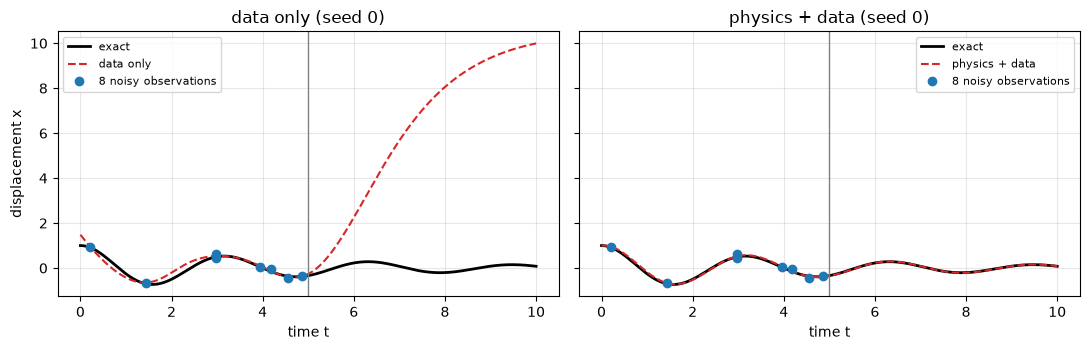

In [4]:
rng = np.random.default_rng(0)
errs_in, errs_out = {"data only": [], "physics + data": []}, {"data only": [], "physics + data": []}
example = {}
for seed in range(3):
    r_ = np.random.default_rng(100 + seed)
    to = np.sort(r_.uniform(0, 5, 8)); xo = osc_exact(to) + 0.05 * r_.normal(size=8)
    for name, mode in [("data only", "data"), ("physics + data", "phys+data")]:
        pred, _ = train_osc(mode, seed, steps=3000, obs=(to, xo), w_data=10.0)
        errs_in[name].append(rel_l2(pred[tt <= 5], xt[tt <= 5])); errs_out[name].append(rel_l2(pred[tt > 5], xt[tt > 5]))
        if seed == 0: example[name] = (pred, to, xo)
print(f"{'model':16s} {'error on [0,5] (data region)':>30s} {'error on (5,10] (extrapolation)':>34s}")
for name in errs_in:
    print(f"{name:16s} {np.mean(errs_in[name]):>20.3f} +- {np.std(errs_in[name]):.3f}   {np.mean(errs_out[name]):>22.3f} +- {np.std(errs_out[name]):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, name in zip(ax, ["data only", "physics + data"]):
    pred, to, xo = example[name]
    a.plot(tt, xt, "k", lw=2, label="exact"); a.plot(tt, pred, "--", color="tab:red", label=name); a.plot(to, xo, "o", color="tab:blue", label="8 noisy observations")
    a.axvline(5, color="gray", lw=1); a.set_xlabel("time t"); a.set_title(name + " (seed 0)"); a.legend(fontsize=8)
ax[0].set_ylabel("displacement x"); plt.tight_layout(); plt.show()

**Reading.** With only 8 noisy points, the network trained on data alone fits them but is useless elsewhere: its relative error was above 1 in the data region (it oscillates between points) and 18 on average outside it (the curve leaves the physical range), with a large spread over the three data sets. Adding the residual, with no initial conditions given, brought the error to about 11 % both inside the data region and in the extrapolated half, so the physics did what the data could not: it chose a damped oscillation and the 8 points chose which one. Two caveats. The weight 10 of the data term was picked after trying 1, 10 and 100 on these same three data sets (with weight 1, one of the three failed with an error near 1), so the number is slightly optimistic. And 11 % is far from the accuracy of a classical fit of the two or three constants of the oscillator, which would use the same physics with a handful of parameters instead of a network; the PINN is the right tool when the model has no such few-parameter form.

## 4. PINN for the heat equation

A PDE needs derivatives in two variables. The network takes the pair $(x,t)$ and returns $u_\theta(x,t)$; autograd gives $u_t$, $u_x$ and $u_{xx}$ (subscripts denote partial derivatives). The loss has three terms: the **PDE residual** $u_t-\nu u_{xx}$ at random interior points, the **boundary condition** $u(0,t)=u(1,t)=0$ and the **initial condition** $u(x,0)=u_0(x)$:

$$\mathcal L=\underbrace{\overline{(u_t-\nu u_{xx})^2}}_{\mathcal L_r}+\lambda\,\underbrace{\Big[\overline{u(0,t)^2}+\overline{u(1,t)^2}+\overline{(u(x,0)-u_0(x))^2}\Big]}_{\mathcal L_b},$$

where the bar is the mean over freshly sampled random points at every step (1,000 interior points, 100 boundary points per side, 200 initial points) and $\lambda$ again weighs the conditions against the equation. Training is again Adam (2,000 steps on fresh random points) followed by L-BFGS (300 iterations on a fixed set of points). We try $\lambda\in\{0.01,1,100\}$ for two seeds (the effect of $\lambda$ is the "gradient pathology" of Wang, Teng and Perdikaris, 2021: when one term dominates the gradients the others are learned slowly) and a fourth variant with **hard constraints**, $u_\theta(x,t)=u_0(x)+t\,x(1-x)\,N_\theta(x,t)$, which equals $u_0$ at $t=0$ and $0$ at $x=0$ and $x=1$ by construction, so only the residual remains in the loss. Then we compare the best with the finite-difference solver in accuracy and in time.

lambda = 0.01    : relative L2 error per seed 1.52e-01, 1.63e-01   (11.7 s per run)


lambda = 1       : relative L2 error per seed 7.49e-03, 5.02e-02   (11.7 s per run)


lambda = 100     : relative L2 error per seed 3.43e-02, 9.18e-03   (11.7 s per run)


hard constraints : relative L2 error per seed 2.56e-04, 3.11e-04   (13.9 s per run)
finite differences 20x20: relative L2 error 3.64e-03, 0.45 ms
finite differences 100x100: relative L2 error 8.49e-05, 2.16 ms


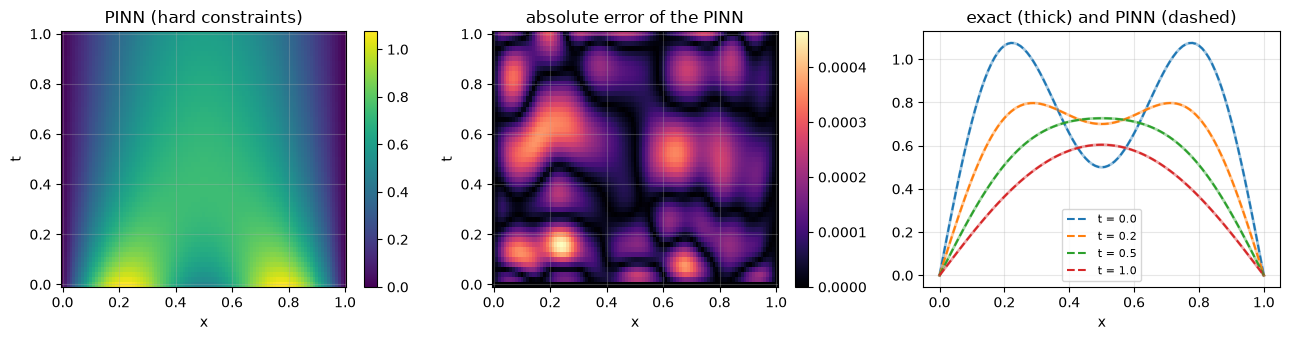

In [5]:
XG, TG = np.meshgrid(np.linspace(0, 1, 101), np.linspace(0, 1, 51))     # evaluation grid (t along rows)
U_EXACT = heat_exact(XG, TG)

def heat_terms(f, P, tb, xi):
    # residual term and condition term of the heat-equation loss for a model f(x, t) -> u
    xt_ = P.clone().requires_grad_(True)                                  # columns: x, t
    u = f(xt_); g = d(u, xt_)
    u_xx = d(g[:, 0:1], xt_)[:, 0:1]
    L_r = ((g[:, 1:2] - NU * u_xx) ** 2).mean()
    u_l = f(torch.cat([torch.zeros_like(tb), tb], 1)); u_r = f(torch.cat([torch.ones_like(tb), tb], 1))
    u_i = f(torch.cat([xi, torch.zeros_like(xi)], 1))
    u0v = torch.sin(math.pi * xi) + 0.5 * torch.sin(3 * math.pi * xi)
    L_b = (u_l ** 2).mean() + (u_r ** 2).mean() + ((u_i - u0v) ** 2).mean()
    return L_r, L_b

def train_heat(seed, w=1.0, adaptive=False, hard=False, steps=2000, lbfgs_iter=300, width=32, n_c=1000):
    # hard=True builds both conditions into the model: u = u0(x) + t x (1 - x) N(x, t) is exactly u0 at t = 0 and 0 at x = 0, 1
    torch.manual_seed(seed)
    net = mlp([2, width, width, width, 1]); params = list(net.parameters())
    if hard:
        f = lambda xt_: (torch.sin(math.pi * xt_[:, 0:1]) + 0.5 * torch.sin(3 * math.pi * xt_[:, 0:1])) + xt_[:, 1:2] * xt_[:, 0:1] * (1 - xt_[:, 0:1]) * net(xt_)
    else:
        f = net
    P = torch.rand(n_c, 2); tb = torch.rand(100, 1); xi = torch.rand(200, 1)        # fixed training points for the L-BFGS stage
    opt = torch.optim.Adam(params, lr=2e-3)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(1e-2) ** (1.0 / steps))
    lam = w; t_start = time.perf_counter(); lam_hist = []
    for s in range(steps):                                                           # stage 1: Adam on fresh random points
        opt.zero_grad()
        L_r, L_b = heat_terms(f, torch.rand(n_c, 2), torch.rand(100, 1), torch.rand(200, 1))
        if adaptive and s % 50 == 0:
            # learning-rate annealing of Wang et al.: scale the condition term so its mean absolute gradient matches that of the residual
            g_r = torch.autograd.grad(L_r, params, retain_graph=True, allow_unused=True)
            g_b = torch.autograd.grad(L_b, params, retain_graph=True, allow_unused=True)
            mean_r = float(torch.cat([g.flatten().abs() for g in g_r if g is not None]).mean())
            mean_b = float(torch.cat([g.flatten().abs() for g in g_b if g is not None]).mean())
            lam = 0.9 * lam + 0.1 * mean_r / (mean_b + 1e-12)
        lam_hist.append(lam)
        (L_r + lam * L_b).backward(); opt.step(); sched.step()
    lbfgs = torch.optim.LBFGS(params, lr=1, max_iter=lbfgs_iter, history_size=50, line_search_fn="strong_wolfe")
    def closure():                                                                   # stage 2: L-BFGS on the fixed points, lambda frozen
        lbfgs.zero_grad(); L_r, L_b = heat_terms(f, P, tb, xi); l = L_r + lam * L_b; l.backward(); return l
    lbfgs.step(closure)
    sec = time.perf_counter() - t_start
    with torch.no_grad():
        pred = f(torch.tensor(np.stack([XG.ravel(), TG.ravel()], 1), dtype=torch.float32)).numpy().reshape(XG.shape)
    return pred, sec, lam_hist

heat_runs = {}
variants = [("lambda = 0.01", dict(w=0.01)), ("lambda = 1", dict(w=1.0)), ("lambda = 100", dict(w=100.0)), ("hard constraints", dict(hard=True))]
for name, kw in variants:
    errs = []
    for seed in range(2):
        pred, sec, _ = train_heat(seed, **kw)
        heat_runs[(name, seed)] = pred; errs.append(rel_l2(pred, U_EXACT))
    print(f"{name:17s}: relative L2 error per seed {errs[0]:.2e}, {errs[1]:.2e}   ({sec:.1f} s per run)")
best_name = min([v[0] for v in variants], key=lambda n: rel_l2(heat_runs[(n, 0)], U_EXACT))
pred_best = heat_runs[(best_name, 0)]; PINN_SEC = sec

# the finite-difference solver on the same evaluation grid
for nx, nt in [(20, 20), (100, 100)]:
    (xg, ug, hist), fd_sec = timed(lambda: heat_fd(nx, nt, keep=True), reps=10)
    interp = RegularGridInterpolator((np.linspace(0, 1, nt + 1), xg), hist)
    fd_pred = interp(np.stack([TG.ravel(), XG.ravel()], 1)).reshape(XG.shape)
    print(f"finite differences {nx}x{nt}: relative L2 error {rel_l2(fd_pred, U_EXACT):.2e}, {fd_sec*1e3:.2f} ms")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
im = ax[0].pcolormesh(XG, TG, pred_best, shading="auto", cmap="viridis"); ax[0].set_title(f"PINN ({best_name})"); plt.colorbar(im, ax=ax[0])
im = ax[1].pcolormesh(XG, TG, np.abs(pred_best - U_EXACT), shading="auto", cmap="magma"); ax[1].set_title("absolute error of the PINN"); plt.colorbar(im, ax=ax[1])
for ti, c in zip([0, 10, 25, 50], ["C0", "C1", "C2", "C3"]):
    ax[2].plot(XG[0], U_EXACT[ti], c, lw=2, alpha=0.4); ax[2].plot(XG[0], pred_best[ti], c + "--", label=f"t = {TG[ti,0]:.1f}")
ax[2].set_title("exact (thick) and PINN (dashed)"); ax[2].legend(fontsize=8)
for a in ax[:2]: a.set_xlabel("x"); a.set_ylabel("t")
ax[2].set_xlabel("x"); plt.tight_layout(); plt.show()

**Reading.** The weighting matters a great deal. With a very small $\lambda=0.01$ the conditions are ignored and the error is 15 % to 16 %; $\lambda=1$ gave 0.7 % and 5 %, and $\lambda=100$ gave 3.4 % and 0.9 %: no fixed value was best for both seeds. The **hard-constraint** version had no weight to tune and was better by one to two orders of magnitude, 2.6e-4 and 3.1e-4 for both seeds, because the conditions are exactly satisfied and the optimiser only has to solve the residual. That is possible here only because the initial profile is a known formula and the domain is a rectangle. Against the classical solver the comparison is sobering: a finite-difference grid of 20 by 20 cells has an error of 3.6e-3 in 0.45 ms and 100 by 100 cells has 8.5e-5 in about 2 ms, while the best PINN needs 12 to 14 s for 2.6e-4. The PINN is thousands of times slower and still less accurate than the 100 by 100 solver. Its attraction is elsewhere: it is mesh-free, differentiable and can mix in measurements, as in the next sections.

## 5. The inverse problem: identify a parameter from noisy data

In the **inverse problem** the equation is known but a coefficient is not: here, the diffusion coefficient $\nu$ of the rod. We are given **300 noisy measurements** $u(x_i,t_i)$ at random points of the space-time domain, noise standard deviation $\sigma\in\{0,0.02,0.1,0.2\}$ (the temperature is of order 1, so $\sigma=0.2$ is large). We do not give the initial profile, which is also unknown.

* **PINN.** Same kind of network as before (Adam then L-BFGS), with $\log\nu$ as an extra trainable parameter (starting from the wrong value $\nu=0.2$), and the loss data mean squared error + 10 times the PDE residual + boundary condition (the residual weight 10 was chosen after a small trial; without it the estimates were similar or worse). The physics fills the space between the measurements.
* **Classical fitting.** Non-linear least squares (`scipy.optimize.least_squares`) over $\nu$ and an unknown initial profile written as a sum of four sines, $u_0=\sum_{k=1}^4 c_k\sin(k\pi x)$ (5 unknowns), where each candidate is evaluated with our Crank-Nicolson solver (64 by 64 cells). It knows the same physics, and it knows the *form* of the profile, which is a favour to it.

We repeat each noise level for 3 random sets of measurements and report the mean absolute error of $\nu$ in percent.

true nu = 0.05.  mean absolute error of the identified nu, in percent (3 repetitions each)
 noise sigma         PINN   classical LS   identified nu per repetition (PINN | classical)
         0.0        39.4%           0.1%   0.0135 0.0283 0.0491 | 0.0500 0.0500 0.0500
        0.02        39.9%           0.5%   0.0170 0.0280 0.0451 | 0.0504 0.0500 0.0497
         0.1        43.3%           2.3%   0.0226 0.0296 0.0328 | 0.0520 0.0501 0.0486
         0.2        45.7%           4.6%   0.0279 0.0264 0.0271 | 0.0540 0.0503 0.0473
time per identification: PINN 11.9 s, classical least squares 0.07 s


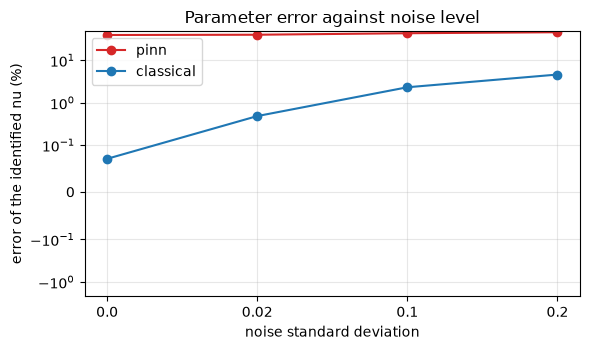

In [6]:
def make_obs(sigma, seed, n=300):
    r_ = np.random.default_rng(seed)
    x = r_.uniform(0, 1, n); t = r_.uniform(0, 1, n)
    return x, t, heat_exact(x, t) + sigma * r_.normal(size=n)

def pinn_inverse(xo, to, uo, seed, steps=2000, nu_init=0.2, lbfgs_iter=300):
    torch.manual_seed(seed)
    net = mlp([2, 32, 32, 32, 1]); log_nu = nn.Parameter(torch.tensor(math.log(nu_init)))
    params = list(net.parameters()) + [log_nu]
    xyo = torch.tensor(np.stack([xo, to], 1), dtype=torch.float32); uo_t = torch.tensor(uo, dtype=torch.float32).reshape(-1, 1)
    def loss_fn(P, tb):
        xt_ = P.clone().requires_grad_(True)
        u = net(xt_); g = d(u, xt_); u_xx = d(g[:, 0:1], xt_)[:, 0:1]
        L_r = ((g[:, 1:2] - torch.exp(log_nu) * u_xx) ** 2).mean()
        L_b = (net(torch.cat([torch.zeros_like(tb), tb], 1)) ** 2).mean() + (net(torch.cat([torch.ones_like(tb), tb], 1)) ** 2).mean()
        return ((net(xyo) - uo_t) ** 2).mean() + 10 * L_r + L_b
    opt = torch.optim.Adam([{"params": list(net.parameters()), "lr": 2e-3}, {"params": [log_nu], "lr": 1e-2}])
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(1e-2) ** (1.0 / steps))
    for s in range(steps):
        opt.zero_grad(); loss_fn(torch.rand(1000, 2), torch.rand(100, 1)).backward(); opt.step(); sched.step()
    P = torch.rand(1000, 2); tb = torch.rand(100, 1)
    lbfgs = torch.optim.LBFGS(params, lr=1, max_iter=lbfgs_iter, history_size=50, line_search_fn="strong_wolfe")
    def closure():
        lbfgs.zero_grad(); l = loss_fn(P, tb); l.backward(); return l
    lbfgs.step(closure)
    return float(torch.exp(log_nu))

def classical_inverse(xo, to, uo, n=64):
    # unknowns: nu and the four sine coefficients of the unknown initial profile
    def model(theta):
        nu, c = theta[0], theta[1:]
        u0 = lambda x: sum(ck * np.sin((k + 1) * np.pi * x) for k, ck in enumerate(c))
        xg, _, hist = heat_fd(n, n, nu=nu, u0=u0, keep=True)
        return RegularGridInterpolator((np.linspace(0, 1, n + 1), xg), hist)(np.stack([to, xo], 1))
    sol = least_squares(lambda th: model(th) - uo, x0=[0.2, 0.5, 0.0, 0.0, 0.0], bounds=([1e-4, -5, -5, -5, -5], [2, 5, 5, 5, 5]))
    return sol.x[0]

sigmas = [0.0, 0.02, 0.1, 0.2]
inv = {s: {"pinn": [], "classical": []} for s in sigmas}
t_pinn = t_cls = 0.0
for sigma in sigmas:
    for seed in range(3):
        xo, to, uo = make_obs(sigma, 500 + seed)
        t1 = time.perf_counter(); inv[sigma]["pinn"].append(pinn_inverse(xo, to, uo, seed)); t_pinn += time.perf_counter() - t1
        t1 = time.perf_counter(); inv[sigma]["classical"].append(classical_inverse(xo, to, uo)); t_cls += time.perf_counter() - t1
print(f"true nu = {NU}.  mean absolute error of the identified nu, in percent (3 repetitions each)")
print(f"{'noise sigma':>12} {'PINN':>12} {'classical LS':>14}   identified nu per repetition (PINN | classical)")
for sigma in sigmas:
    ep = [100 * abs(v - NU) / NU for v in inv[sigma]["pinn"]]; ec = [100 * abs(v - NU) / NU for v in inv[sigma]["classical"]]
    print(f"{sigma:>12} {np.mean(ep):>11.1f}% {np.mean(ec):>13.1f}%   " + " ".join(f"{v:.4f}" for v in inv[sigma]["pinn"]) + " | " + " ".join(f"{v:.4f}" for v in inv[sigma]["classical"]))
print(f"time per identification: PINN {t_pinn/12:.1f} s, classical least squares {t_cls/12:.2f} s")

fig, ax = plt.subplots(figsize=(6, 3.6))
for key, c in [("pinn", "tab:red"), ("classical", "tab:blue")]:
    m = [np.mean([100 * abs(v - NU) / NU for v in inv[s][key]]) for s in sigmas]
    ax.plot(range(len(sigmas)), m, "o-", color=c, label=key)
ax.set_xticks(range(len(sigmas))); ax.set_xticklabels([str(s) for s in sigmas]); ax.set_yscale("symlog", linthresh=0.1)
ax.set_xlabel("noise standard deviation"); ax.set_ylabel("error of the identified nu (%)"); ax.legend(); ax.set_title("Parameter error against noise level")
plt.tight_layout(); plt.show()

**Reading.** The result is a clear negative for the PINN in this setting. Classical least squares recovered $\nu$ to 0.1 % without noise, and its error grew with the noise as it should (0.5 %, 2.3 % and 4.6 % for $\sigma=0.02$, 0.1 and 0.2), in 0.07 s per fit. The PINN's error was 39 % to 46 % at every noise level, with estimates between 0.014 and 0.049 for a true value of 0.05, mostly too low, and each fit took 12 s. Because the PINN error does not grow with the noise, it is not a noise effect: it is an optimisation bias of our small budget (2,000 Adam steps and 300 L-BFGS iterations for a network of 32 units). A plausible, untested explanation is that an under-fitted network has an irregular second derivative and the residual loss can be lowered by shrinking $\nu$. We tried a longer run, a heavier residual weight, a data-only warm-up and giving the initial profile, and the estimates stayed biased low, so we do not claim it is easy to fix. Published PINN identifications succeed with larger budgets and tuned problems, but this is the experience of a first implementation. The practical rule is that **when you have a solver and a correct model, fit with the solver**; use a PINN when you do not have one, when the model is awkward to differentiate through, or when you need the parameter inside a larger network, and then check the identification against a held-out set of measurements.

## 6. When PINNs fail, and the remedies

PINNs have a reputation for being easy to write and hard to train. Three failure modes explain most of the trouble; we show each one with a measurement and try the standard remedy.

### 6.1 Spectral bias and Fourier features

Neural networks learn low frequencies first (**spectral bias**). We ask a network to solve the trivial ODE $\dot u=\omega\cos(\omega t)$, $u(0)=0$ on $[0,2\pi]$ (exact solution $u=\sin\omega t$, with $\omega$ the angular frequency of the target; the initial condition is imposed as a hard constraint $u=t\,N(t)$) and increase $\omega$. The remedy of Tancik et al. (2020) is **Fourier features**: feed the network $[t,\sin(Bt),\cos(Bt)]$ with a fixed random vector $B$ of 32 frequencies drawn from a normal distribution of standard deviation $\sigma_F$ (sigma F), so that high frequencies are available from the start. The scale $\sigma_F$ is a hyper-parameter, and a bad one hurts, so we sweep $\sigma_F\in\{2,5,10\}$ ($\sigma_F=0$ is the plain network).

relative L2 error of the PINN solution of u' = omega cos(omega t) (1 seed); sigma_F = 0 is the plain MLP
 omega    sigma_F = 0    sigma_F = 2    sigma_F = 5   sigma_F = 10


     1       6.23e-03       7.20e-04       8.03e-03       2.69e-01


     4       1.62e-02       8.00e-04       2.06e-02       3.10e-01


    10       9.64e-01       4.95e-02       1.29e-01       5.67e-01


    20       1.01e+00       2.72e-01       4.71e-01       5.62e-01


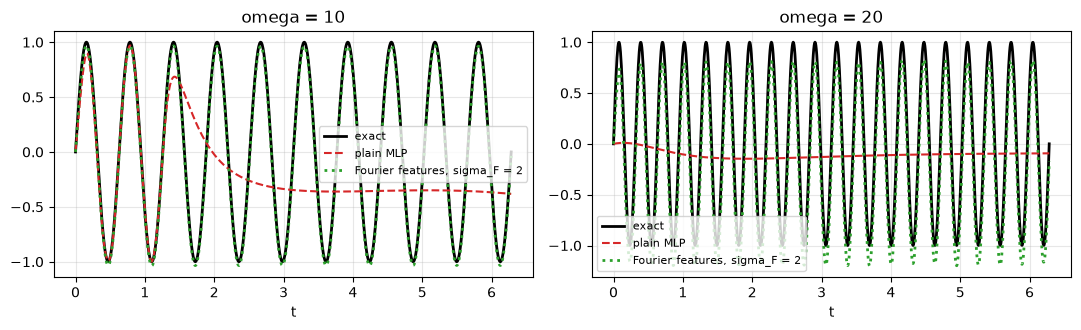

In [7]:
def train_freq(omega, sigma_f, seed=0, steps=2000):
    # sigma_f = 0 means a plain MLP; otherwise the input is [t, sin(Bt), cos(Bt)] with 32 random frequencies B ~ N(0, sigma_f^2)
    torch.manual_seed(seed)
    B = torch.randn(32) * sigma_f
    feat = (lambda t: torch.cat([t, torch.sin(t * B), torch.cos(t * B)], 1)) if sigma_f else (lambda t: t)
    net = mlp([65 if sigma_f else 1, 64, 64, 64, 1])
    u = lambda t: t * net(feat(t))                                  # hard constraint u(0) = 0
    opt = torch.optim.Adam(net.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(1e-2) ** (1.0 / steps))
    for s in range(steps):
        opt.zero_grad()
        t = (torch.rand(512, 1) * 2 * math.pi).requires_grad_(True)
        loss = ((d(u(t), t) - omega * torch.cos(omega * t)) ** 2).mean()
        loss.backward(); opt.step(); sched.step()
    tg = torch.linspace(0, 2 * math.pi, 1000).reshape(-1, 1)
    with torch.no_grad(): pred = u(tg).numpy().ravel()
    return tg.numpy().ravel(), pred

omegas = [1, 4, 10, 20]; sigmas_f = [0, 2, 5, 10]
freq_res = {}
print("relative L2 error of the PINN solution of u' = omega cos(omega t) (1 seed); sigma_F = 0 is the plain MLP")
print(f"{'omega':>6} " + " ".join(f"{'sigma_F = ' + str(sf):>14}" for sf in sigmas_f))
for om in omegas:
    row = []
    for sf in sigmas_f:
        tg, pred = train_freq(om, sf); freq_res[(om, sf)] = pred; row.append(rel_l2(pred, np.sin(om * tg)))
    print(f"{om:>6} " + " ".join(f"{e:>14.2e}" for e in row))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, om in zip(ax, [10, 20]):
    a.plot(tg, np.sin(om * tg), "k", lw=2, label="exact"); a.plot(tg, freq_res[(om, 0)], "--", color="tab:red", label="plain MLP")
    a.plot(tg, freq_res[(om, 2)], ":", color="tab:green", lw=2, label="Fourier features, sigma_F = 2"); a.set_title(f"omega = {om}"); a.set_xlabel("t"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading.** Spectral bias is visible and strong: the plain network solves $\omega=1$ and $\omega=4$ (errors of 0.6 % and 1.6 %) and fails completely at $\omega=10$ and 20 (errors of 0.96 and 1.0, it outputs something smooth that has nothing to do with the target). With Fourier features at $\sigma_F=2$ the error drops to 0.07 % and 0.08 % at low frequency, 5 % at $\omega=10$ and 27 % at $\omega=20$, a large gain that is still not a solution at $\omega=20$. The scale matters: $\sigma_F=5$ is worse at every frequency than $\sigma_F=2$, and $\sigma_F=10$ is worse than the plain network at $\omega=1$ and 4 (27 % and 31 %), because random high frequencies fit noise between the collocation points. The remedy works only when the scale of the features is matched to the target, which means knowing something about the solution in advance. One seed per cell.

### 6.2 Loss imbalance and adaptive weights

Section 4 showed that the weight $\lambda$ of the conditions against the equation changes the result and has to be tuned. **Adaptive weighting** (the learning-rate annealing of Wang, Teng and Perdikaris, 2021) removes that hyper-parameter: every 50 steps it sets $\lambda$ so that the mean absolute gradient of the condition term matches that of the residual term (Wang et al. use the largest gradient of the residual; the mean is a simpler variant that was more stable in our tests, where the maximum drove $\lambda$ above 1,000). The cell below repeats the heat PINN with this rule, starting from $\lambda=1$, and compares it with the fixed weights of section 4.

heat equation PINN, relative L2 error (2 seeds)
  lambda = 0.01    : 1.52e-01, 1.63e-01
  lambda = 1       : 7.49e-03, 5.02e-02
  lambda = 100     : 3.43e-02, 9.18e-03
  hard constraints : 2.56e-04, 3.11e-04
  adaptive lambda  : 7.61e-03, 1.09e-01   (lambda at the end: 0.3, 0.1)


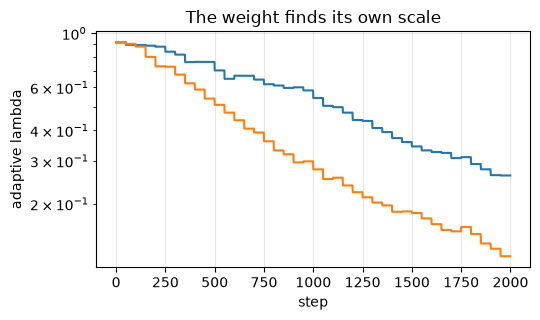

In [8]:
ad_errs, ad_lams = [], []
for seed in range(2):
    pred, sec, lam_hist = train_heat(seed, adaptive=True)
    ad_errs.append(rel_l2(pred, U_EXACT)); ad_lams.append(lam_hist)
print("heat equation PINN, relative L2 error (2 seeds)")
for name, _ in variants:
    print(f"  {name:17s}: " + ", ".join(f"{rel_l2(heat_runs[(name, s)], U_EXACT):.2e}" for s in range(2)))
print("  adaptive lambda  : " + ", ".join(f"{e:.2e}" for e in ad_errs) + f"   (lambda at the end: {ad_lams[0][-1]:.1f}, {ad_lams[1][-1]:.1f})")
fig, ax = plt.subplots(figsize=(5.5, 3.3))
for h in ad_lams: ax.semilogy(h)
ax.set_xlabel("step"); ax.set_ylabel("adaptive lambda"); ax.set_title("The weight finds its own scale"); plt.tight_layout(); plt.show()

**Reading.** The adaptive rule found a usable scale on its own: starting from $\lambda=1$ it settled at $\lambda=0.3$ and 0.1 and the errors were 0.8 % and 11 %. Compared with the fixed weights of section 4 this is as good as the best fixed value for seed 0 and worse than $\lambda=1$ for seed 1 (5 %), so the benefit is **not having to guess the scale** (the wrong guess $\lambda=0.01$ gave 15 %), not a higher accuracy than a well-chosen weight. The version in the original paper, which uses the largest residual gradient, made $\lambda$ grow into the thousands in our first tests and gave worse errors, so the variant we use is a deliberate simplification. With two seeds, the difference between the adaptive and the best fixed weight is within the seed-to-seed variation, so we do not claim an advantage. The hard constraint of section 4 (2.6e-4) beats every weighting scheme when it is available.

### 6.3 Stiff problems, long horizons, causal training and Fourier features in time

Krishnapriyan et al. (2021) show that PINNs fail on problems that look innocent. Their standard example is the **convection equation** $u_t+\beta u_x=0$ on the periodic domain $x\in[0,2\pi]$ with $u(x,0)=\sin x$, where $\beta$ (beta) is the wave speed. The solution is just a travelling sine, $u=\sin(x-\beta t)$, but as $\beta$ grows the network must represent more oscillations in $t\in[0,1]$ and the residual becomes a very stiff, multi-scale loss landscape.

We test three versions of the same network and the same budget (Adam, then L-BFGS), for $\beta\in\{1,10,30\}$:

* **plain**: the residual is averaged over all times;
* **causal training** (Wang, Sankaran and Perdikaris, 2022), which respects the arrow of time: split $[0,1]$ into $M=16$ bins with mean residual losses $\mathcal L_i$ and weight bin $i$ by $w_i=\exp\!\big(-\varepsilon\sum_{k<i}\mathcal L_k\big)$ (with $\varepsilon$, epsilon, a positive constant, here 1; the weights are treated as constants in the gradient). A bin counts only after all earlier bins have a small residual. This was designed for long time horizons, where a network can lower the loss at late times while the early times are still wrong;
* **Fourier features in $t$**: the plain loss but with the input $[\sin x,\cos x,t,\sin(Bt),\cos(Bt)]$ where $B$ has 16 random frequencies of standard deviation $0.3\beta$. The stiffness is, in large part, spectral bias along the time axis, so the remedy of section 6.1 should apply; the scale is again a choice we made knowing $\beta$.

All three use the same sampling of 64 points per time bin, and we report one seed (this section is the most expensive one).

relative L2 error on the whole space-time domain (1 seed), Adam 3000 steps then L-BFGS
 beta      plain     causal  Fourier in t


    1   6.98e-04        nan           nan


   10   2.64e-01   1.85e-01      1.06e-02


   30   9.35e-01   9.36e-01      5.35e-01
(152 s for all runs)


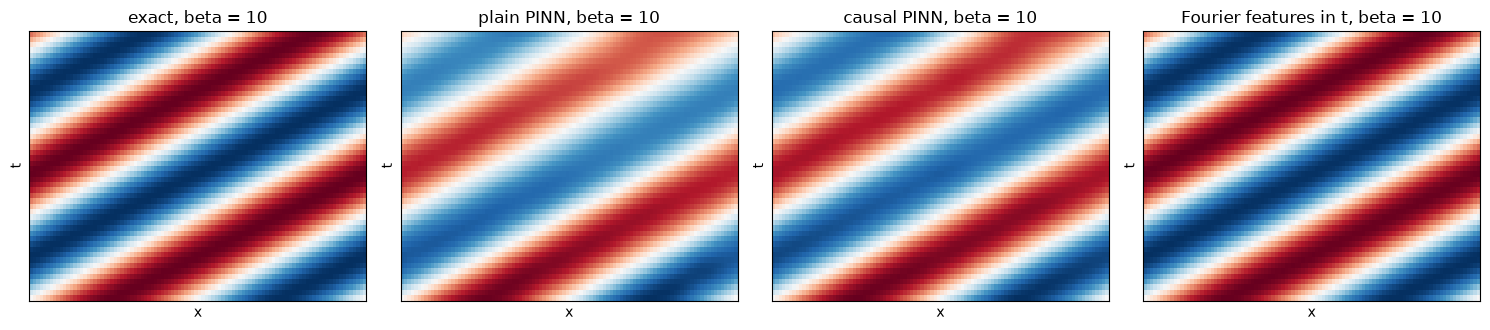

In [9]:
def train_conv(beta, mode, seed=0, steps=3000, lbfgs_iter=300, eps=1.0, M=16, k=64):
    # mode: "plain", "causal" (time-ordered weights) or "fourier" (plain loss, Fourier features of t with scale 0.3 beta)
    torch.manual_seed(seed)
    B = torch.randn(16) * 0.3 * beta
    def feats(x, t):
        z = [torch.sin(x), torch.cos(x), t]                              # sin x, cos x make the net periodic in x
        if mode == "fourier": z += [torch.sin(t * B), torch.cos(t * B)]
        return torch.cat(z, 1)
    net = mlp([35 if mode == "fourier" else 3, 64, 64, 64, 1]); f = lambda x, t: net(feats(x, t))
    bins = torch.arange(M).reshape(M, 1).float()
    def loss_fn(t, x, xi):
        t = t.clone().requires_grad_(True); x = x.clone().requires_grad_(True)
        u = f(x, t)
        L_i = (((d(u, t) + beta * d(u, x)) / beta) ** 2).reshape(M, k).mean(1)   # residual per time bin (divided by beta to keep the scale)
        w = torch.exp(-eps * (torch.cumsum(L_i, 0) - L_i)).detach() if mode == "causal" else torch.ones(M)   # earlier bins only
        L_ic = ((f(xi, torch.zeros_like(xi)) - torch.sin(xi)) ** 2).mean()
        return (w * L_i).mean() + L_ic
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(1e-2) ** (1.0 / steps))
    for s in range(steps):
        opt.zero_grad()
        loss_fn((bins + torch.rand(M, k)).div(M).reshape(-1, 1), torch.rand(M * k, 1) * 2 * math.pi, torch.rand(200, 1) * 2 * math.pi).backward()
        opt.step(); sched.step()
    tf = (bins + torch.rand(M, k)).div(M).reshape(-1, 1); xf = torch.rand(M * k, 1) * 2 * math.pi; xif = torch.rand(200, 1) * 2 * math.pi
    lbfgs = torch.optim.LBFGS(net.parameters(), lr=1, max_iter=lbfgs_iter, history_size=50, line_search_fn="strong_wolfe")
    def closure():
        lbfgs.zero_grad(); l = loss_fn(tf, xf, xif); l.backward(); return l
    lbfgs.step(closure)
    xg_, tg_ = np.meshgrid(np.linspace(0, 2 * np.pi, 100), np.linspace(0, 1, 50))
    with torch.no_grad():
        pred = f(torch.tensor(xg_.ravel(), dtype=torch.float32).reshape(-1, 1), torch.tensor(tg_.ravel(), dtype=torch.float32).reshape(-1, 1)).numpy().reshape(xg_.shape)
    return pred, np.sin(xg_ - beta * tg_)

conv = {}; t_conv = time.perf_counter()
print("relative L2 error on the whole space-time domain (1 seed), Adam 3000 steps then L-BFGS")
print(f"{'beta':>5} {'plain':>10} {'causal':>10} {'Fourier in t':>13}")
for beta in [1, 10, 30]:
    row = []
    for mode in ["plain", "causal", "fourier"]:
        if beta == 1 and mode != "plain":
            row.append(float("nan")); continue
        pred, true = train_conv(beta, mode); conv[(beta, mode)] = pred; row.append(rel_l2(pred, true))
    print(f"{beta:>5} {row[0]:>10.2e} {row[1]:>10.2e} {row[2]:>13.2e}")
print(f"({time.perf_counter() - t_conv:.0f} s for all runs)")
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
xg_, tg_ = np.meshgrid(np.linspace(0, 2 * np.pi, 100), np.linspace(0, 1, 50))
panels = [("exact, beta = 10", np.sin(xg_ - 10 * tg_)), ("plain PINN", conv[(10, "plain")]), ("causal PINN", conv[(10, "causal")]), ("Fourier features in t", conv[(10, "fourier")])]
for a, (name, z) in zip(ax, panels):
    a.pcolormesh(z, cmap="RdBu_r", vmin=-1, vmax=1); a.set_title(name + ("" if name.startswith("exact") else ", beta = 10")); a.set_xlabel("x"); a.set_ylabel("t"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**Reading.** For the mild case $\beta=1$ the plain PINN is accurate (7e-4). At $\beta=10$ the plain PINN fails (relative error 0.26) and at $\beta=30$ it has no skill (0.94, the wrong function everywhere): the stiffness failure of Krishnapriyan et al. reproduced in a small setting. **Causal training did not rescue it**: 0.19 at $\beta=10$ (a modest gain that one seed cannot confirm) and no change at $\beta=30$. We also tried other values of $\varepsilon$ and found that large values stop the training of late times altogether; this is not a refutation of the method, whose published gains are for long-time chaotic and turbulent problems, but it shows that it is not a general cure and that our problem is limited by the frequency content in time, not by the order of events. The remedy that did work is the one of section 6.1: **Fourier features in $t$** brought $\beta=10$ from 0.26 to 0.011, a 25-fold improvement, and halved the error at $\beta=30$ (0.54) without solving it. Note that the scale of the features (0.3 $\beta$) used our knowledge of $\beta$, as in section 6.1. One seed per cell, so differences of a factor of two are not reliable, but the 25-fold gain and the plain-versus-Fourier ordering at $\beta=10$ are far beyond what seed noise is likely to explain.

## 7. Neural operators: learn the solution map

A PINN solves **one** instance: change the initial condition and you retrain. Many applications need the answer for **thousands of different inputs**. A **neural operator** learns the **solution operator** $\mathcal G$ (calligraphic G), the map from an input function to the solution function, for example from the initial condition $u_0(x)$ to the solution at a later time, $u(\cdot,T)=\mathcal G(u_0)$. It is trained on pairs produced by a classical solver, so it does not need the equation, and once trained a new instance costs one forward pass.

Our test case is the **viscous Burgers equation**, a one-dimensional fluid with a nonlinear term that steepens waves into shocks and a viscosity that smooths them:

$$u_t+u\,u_x=\nu\,u_{xx},\qquad x\in[0,1)\text{ periodic},\quad \nu=0.02,\quad T=1.$$

We write the solver ourselves: a **pseudo-spectral** method (derivatives by the fast Fourier transform, FFT) with the exact exponential for the viscous term and a fourth-order Runge-Kutta step for the nonlinear one (the integrating-factor scheme), the 2/3 rule to remove aliasing, 128 grid points and 500 time steps. Initial conditions are random smooth functions, $u_0(x)=\sum_{m=1}^{M}\big(a_m\cos 2\pi mx+b_m\sin 2\pi mx\big)$ with $a_m,b_m\sim\mathcal N(0,s_m^2)$, $s_m=0.6/(1+m)$ and $M=12$ modes (in-distribution). We check the solver against a finer grid and a halved time step before using it as ground truth.

solver check: time step halved -> relative difference 3.8e-09; 256 instead of 128 points -> 5.8e-15


generated 1000 training pairs in 1.5 s with the solver (batched, 128 points); training grid 64 points
relative L2 distance between u(T) and u(0) (the 'do nothing' baseline): 0.88


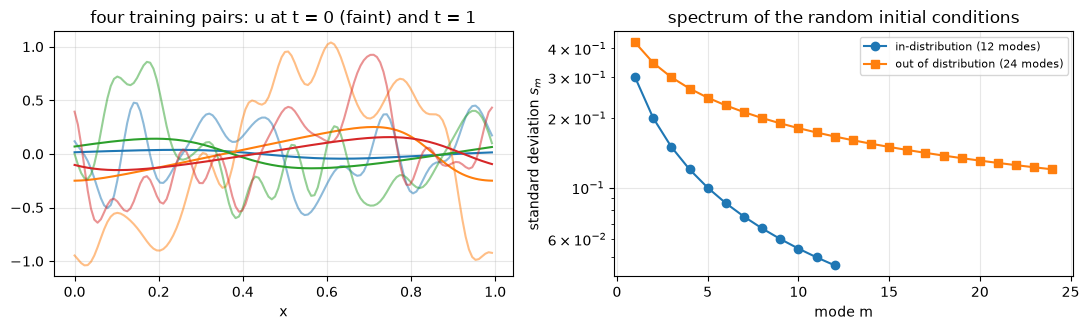

In [10]:
NU_B, T_B = 0.02, 1.0

def burgers_solve(u0, nu=NU_B, T=T_B, dt=2e-3):
    # u0: (batch, N) on the periodic grid x_j = j/N. Integrating-factor RK4, pseudo-spectral, 2/3 dealiasing
    B, N = u0.shape
    k = np.fft.rfftfreq(N, 1.0 / N) * 2 * np.pi
    E = np.exp(-nu * k**2 * dt / 2); E2 = E * E
    mask = np.arange(len(k)) <= N // 3
    nl = lambda v: -1j * k * np.fft.rfft(0.5 * np.fft.irfft(v, n=N) ** 2) * mask       # -(u^2/2)_x in Fourier space
    v = np.fft.rfft(u0)
    for _ in range(int(round(T / dt))):
        k1 = nl(v); k2 = nl(E * (v + dt / 2 * k1)); k3 = nl(E * v + dt / 2 * k2); k4 = nl(E2 * v + dt * E * k3)
        v = E2 * v + dt / 6 * (E2 * k1 + 2 * E * (k2 + k3) + k4)
    return np.fft.irfft(v, n=N)

def sample_ic(n, M, amp, p, rng):
    m = np.arange(1, M + 1); s = amp / (1 + m) ** p
    return rng.normal(size=(n, M)) * s, rng.normal(size=(n, M)) * s

def eval_ic(a, b, N):
    x = np.arange(N) / N; m = np.arange(1, a.shape[1] + 1)
    return a @ np.cos(2 * np.pi * np.outer(m, x)) + b @ np.sin(2 * np.pi * np.outer(m, x))

rng = np.random.default_rng(0)
A_tr, B_tr = sample_ic(1000, 12, 0.6, 1.0, rng)          # training initial conditions
A_te, B_te = sample_ic(100, 12, 0.6, 1.0, rng)           # new initial conditions, same distribution
A_od, B_od = sample_ic(100, 24, 0.6, 0.5, rng)           # out of distribution: more modes, slower spectral decay, larger amplitude

# solver verification on 20 test initial conditions
u_a = burgers_solve(eval_ic(A_te[:20], B_te[:20], 128))
u_b = burgers_solve(eval_ic(A_te[:20], B_te[:20], 128), dt=1e-3)
u_c = burgers_solve(eval_ic(A_te[:20], B_te[:20], 256))
print(f"solver check: time step halved -> relative difference {rel_l2(u_a, u_b):.1e}; 256 instead of 128 points -> {rel_l2(u_c[:, ::2], u_a):.1e}")

t0 = time.perf_counter()
U0_128 = eval_ic(A_tr, B_tr, 128); UT_128 = burgers_solve(U0_128)
T_GEN = time.perf_counter() - t0
U0_tr, UT_tr = U0_128[:, ::2], UT_128[:, ::2]            # training data live on a 64-point grid
test = {}
for name, (A, Bc) in [("in-distribution", (A_te, B_te)), ("out of distribution", (A_od, B_od))]:
    for N in [64, 128, 256]:
        u0_ = eval_ic(A, Bc, N); test[(name, N)] = (u0_, burgers_solve(u0_))
print(f"generated {len(U0_tr)} training pairs in {T_GEN:.1f} s with the solver (batched, 128 points); training grid 64 points")
print(f"relative L2 distance between u(T) and u(0) (the 'do nothing' baseline): {rel_l2(UT_tr, U0_tr):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
xg = np.arange(128) / 128
for i in range(4):
    ax[0].plot(xg, U0_128[i], color=f"C{i}", alpha=0.5); ax[0].plot(xg, UT_128[i], color=f"C{i}")
ax[0].set_title("four training pairs: u at t = 0 (faint) and t = 1"); ax[0].set_xlabel("x")
ax[1].plot(np.arange(1, 13), 0.6 / (1 + np.arange(1, 13)), "o-", label="in-distribution (12 modes)")
ax[1].plot(np.arange(1, 25), 0.6 / (1 + np.arange(1, 25)) ** 0.5, "s-", label="out of distribution (24 modes)")
ax[1].set_yscale("log"); ax[1].set_xlabel("mode m"); ax[1].set_ylabel("standard deviation $s_m$"); ax[1].legend(fontsize=8); ax[1].set_title("spectrum of the random initial conditions")
plt.tight_layout(); plt.show()

### DeepONet and the Fourier neural operator

**DeepONet** (Lu et al., 2021) is built on the universal approximation theorem for operators. A **branch network** reads the input function sampled at $m=64$ fixed sensor points and outputs $p$ coefficients $b_k(u_0)$; a **trunk network** reads the query position $x$ and outputs $p$ basis functions $\tau_k(x)$ (tau); the solution is their inner product,

$$\mathcal G(u_0)(x)\approx\sum_{k=1}^{p} b_k(u_0)\,\tau_k(x)+b_0 .$$

The trunk can be evaluated at *any* $x$, but the branch needs the input on the sensor grid. We give the trunk periodic features $[\sin 2\pi x,\cos 2\pi x,\sin 4\pi x]$ as a convenience.

The **Fourier neural operator** (FNO; Li et al., 2021) works with the input as a function on a grid. Each **Fourier layer** takes the FFT of its input, multiplies the lowest $K$ modes by a learned complex matrix (a global convolution), transforms back, adds a pointwise linear map of the input and applies a nonlinearity: $v\mapsto\sigma\big(\mathcal F^{-1}(R_\phi\cdot\mathcal F v)+Wv\big)$, with $\mathcal F$ the Fourier transform and $R_\phi$ the learned complex weights. Because the weights act on **modes** and not on grid points, the same network can be applied to a grid of any resolution. We use width 24, $K=12$ modes, four layers. As a third baseline, a plain **MLP** maps the 64 input values to the 64 output values (it is tied to this grid). All three are trained with Adam and a one-cycle learning-rate schedule on batches of 50, with a loss equal to the relative L2 error of each sample; the FNO gets 100 epochs and the two cheaper baselines 400 epochs, so that the comparison is roughly at equal training time rather than equal epochs.

FNO         60,265 real parameters, trained in 25 s, final training loss 0.0022


DeepONet    58,369 real parameters, trained in 14 s, final training loss 0.0104


MLP        164,672 real parameters, trained in 15 s, final training loss 0.0062

mean relative L2 error on 100 test initial conditions (training grid = 64 points)
test set                grid      FNO  DeepONet      MLP
in-distribution           64   0.0023    0.0221   0.0147
in-distribution          128   0.0023    0.0221      n/a
in-distribution          256   0.0023    0.0221      n/a
out of distribution       64   0.0577    0.1913   0.1452
out of distribution      128   0.0579    0.1913      n/a
out of distribution      256   0.0579    0.1913      n/a


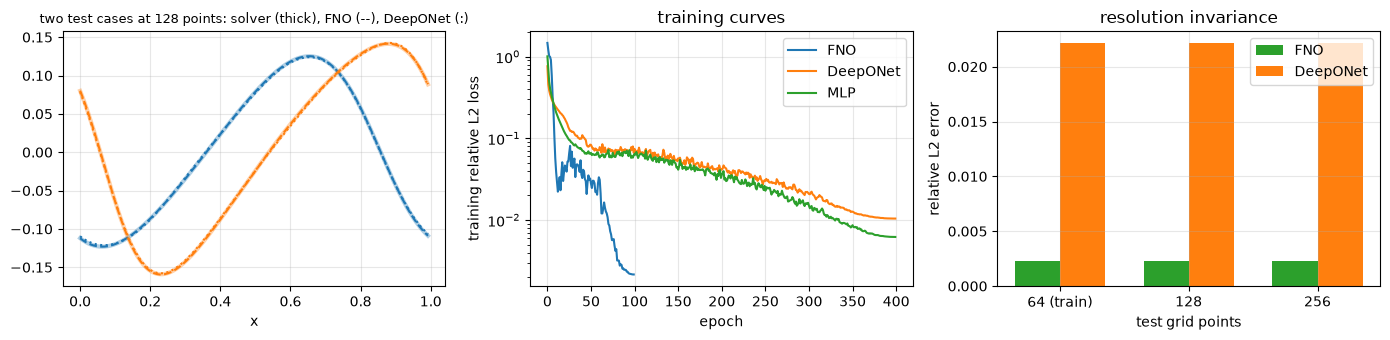

In [11]:
class SpectralConv1d(nn.Module):
    def __init__(self, cin, cout, modes):
        super().__init__()
        self.modes = modes
        self.w = nn.Parameter(torch.randn(cin, cout, modes, dtype=torch.cfloat) / (cin * cout) ** 0.5 * 0.5)
    def forward(self, x):                                       # x: (batch, channels, N)
        xf = torch.fft.rfft(x)
        out = torch.zeros(x.shape[0], self.w.shape[1], xf.shape[-1], dtype=torch.cfloat)
        out[:, :, :self.modes] = torch.einsum("bim,iom->bom", xf[:, :, :self.modes], self.w)
        return torch.fft.irfft(out, n=x.shape[-1])

class FNO1d(nn.Module):
    def __init__(self, width=24, modes=12, layers=4):
        super().__init__()
        self.lift = nn.Conv1d(2, width, 1)
        self.spec = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(layers)])
        self.pw = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(layers)])
        self.proj = nn.Sequential(nn.Conv1d(width, 96, 1), nn.GELU(), nn.Conv1d(96, 1, 1))
    def forward(self, u0):                                      # u0: (batch, N), any N
        N = u0.shape[1]; grid = (torch.arange(N, dtype=torch.float32) / N).expand(u0.shape[0], N)
        h = self.lift(torch.stack([u0, grid], 1))
        for s, p in zip(self.spec, self.pw):
            h = torch.nn.functional.gelu(s(h) + p(h))
        return self.proj(h)[:, 0]

class DeepONet(nn.Module):
    def __init__(self, m=64, p=64, h=128):
        super().__init__()
        self.m = m; self.branch = mlp([m, h, h, p], nn.GELU); self.trunk = mlp([3, h, h, p], nn.GELU); self.b0 = nn.Parameter(torch.zeros(1))
    def forward(self, u0):                                      # the branch reads m fixed sensors, the trunk any number of query points
        N = u0.shape[1]; sensors = u0[:, ::N // self.m]
        x = torch.arange(N, dtype=torch.float32) / N
        tf = torch.stack([torch.sin(2 * math.pi * x), torch.cos(2 * math.pi * x), torch.sin(4 * math.pi * x)], 1)
        return self.branch(sensors) @ self.trunk(tf).T + self.b0

class MLPOperator(nn.Module):
    def __init__(self, n=64, h=256):
        super().__init__(); self.net = mlp([n, h, h, h, n], nn.GELU)
    def forward(self, u0): return self.net(u0)

def rel_loss(pred, true):
    return (torch.linalg.norm(pred - true, dim=1) / torch.linalg.norm(true, dim=1)).mean()

def fit_operator(model, epochs=100, bs=50, lr=3e-3, seed=0):
    torch.manual_seed(seed)
    X = torch.tensor(U0_tr, dtype=torch.float32); Y = torch.tensor(UT_tr, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * (len(X) // bs))
    t_start = time.perf_counter(); curve = []
    for ep in range(epochs):
        perm = torch.randperm(len(X)); tot = 0.0
        for i in range(0, len(X) - bs + 1, bs):
            idx = perm[i:i + bs]; opt.zero_grad()
            loss = rel_loss(model(X[idx]), Y[idx]); loss.backward(); opt.step(); sched.step(); tot += float(loss)
        curve.append(tot / (len(X) // bs))
    return time.perf_counter() - t_start, curve

models = {"FNO": FNO1d(), "DeepONet": DeepONet(), "MLP": MLPOperator()}
train_sec, curves = {}, {}
for name, mdl in models.items():
    torch.manual_seed(0)
    n_par = sum(p.numel() if not p.is_complex() else 2 * p.numel() for p in mdl.parameters())
    train_sec[name], curves[name] = fit_operator(mdl, epochs=100 if name == "FNO" else 400)
    print(f"{name:9s} {n_par:>8,d} real parameters, trained in {train_sec[name]:.0f} s, final training loss {curves[name][-1]:.4f}")

@torch.no_grad()
def predict(mdl, u0):
    return mdl(torch.tensor(u0, dtype=torch.float32)).numpy()

def mean_rel(pred, true):
    return float(np.mean(np.linalg.norm(pred - true, axis=1) / np.linalg.norm(true, axis=1)))

print("\nmean relative L2 error on 100 test initial conditions (training grid = 64 points)")
print(f"{'test set':22s} {'grid':>5} {'FNO':>8} {'DeepONet':>9} {'MLP':>8}")
table = {}
for name in ["in-distribution", "out of distribution"]:
    for N in [64, 128, 256]:
        u0_, uT_ = test[(name, N)]
        row = [mean_rel(predict(models["FNO"], u0_), uT_), mean_rel(predict(models["DeepONet"], u0_), uT_)]
        row.append(mean_rel(predict(models["MLP"], u0_), uT_) if N == 64 else float("nan"))
        table[(name, N)] = row
        print(f"{name:22s} {N:>5} {row[0]:>8.4f} {row[1]:>9.4f} {row[2]:>8.4f}" if N == 64 else f"{name:22s} {N:>5} {row[0]:>8.4f} {row[1]:>9.4f}      n/a")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
u0_, uT_ = test[("in-distribution", 128)]; xg = np.arange(128) / 128
for j, i in enumerate([0, 1]):
    ax[0].plot(xg, uT_[i], f"C{j}", lw=3, alpha=0.35); ax[0].plot(xg, predict(models["FNO"], u0_)[i], f"C{j}--"); ax[0].plot(xg, predict(models["DeepONet"], u0_)[i], f"C{j}:")
ax[0].set_title("two test cases at 128 points: solver (thick), FNO (--), DeepONet (:)"); ax[0].set_xlabel("x"); ax[0].title.set_fontsize(9)
for name in models: ax[1].semilogy(curves[name], label=name)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("training relative L2 loss"); ax[1].legend(); ax[1].set_title("training curves")
w = 0.35
for j, (name, c) in enumerate([("FNO", "tab:green"), ("DeepONet", "tab:orange")]):
    ax[2].bar(np.arange(3) + (j - 0.5) * w, [table[("in-distribution", N)][j] for N in [64, 128, 256]], w, color=c, label=name)
ax[2].set_xticks(range(3)); ax[2].set_xticklabels(["64 (train)", "128", "256"]); ax[2].set_xlabel("test grid points"); ax[2].set_ylabel("relative L2 error"); ax[2].legend(); ax[2].set_title("resolution invariance")
plt.tight_layout(); plt.show()

**Reading.** The FNO learned the solution map well: the mean relative error on 100 new initial conditions was 0.23 %, against 1.5 % for the plain MLP and 2.2 % for the DeepONet (the "do nothing" baseline is 0.88), with about 60,000 weights in the FNO and DeepONet and 165,000 in the MLP. The baselines were given four times as many epochs to compare at roughly equal training time (14 to 15 s against 25 s), and one seed was run for each model, so the ranking is a measurement and not a general law. On the finer grids of 128 and 256 points the FNO error is the same, 0.23 %, which is **resolution invariance**: the network never saw those grids. The DeepONet also gives the same number at every grid, but for a different reason: it only reads its 64 sensor values and the finer grid adds no information, while the MLP cannot be applied to another grid at all. Be careful with the claim for the FNO: our solution is band-limited, so a finer grid contains no new fine scales and an identical error is what one expects; it would not mean that the network can invent unresolved structure. **Out of distribution** (more modes, slower spectral decay, larger amplitude), every model degrades: the FNO to 5.8 % (25 times its own in-distribution error), the MLP to 15 % and the DeepONet to 19 %. A neural operator is only as good as the family of inputs it was trained on.

### Speed against the solver

The promise of a surrogate is speed. We time one solver run (one initial condition, 128 points), the solver on a batch of 100 initial conditions (it is vectorised, so this is a strong baseline), and the FNO on a batch of 100. Then we count how many solutions you must need before the whole investment (generating data and training) pays off.

In [12]:
u0_, uT_ = test[("in-distribution", 128)]
_, t_single = timed(lambda: burgers_solve(u0_[:1]), reps=5)
_, t_batch = timed(lambda: burgers_solve(u0_), reps=3)
x_t = torch.tensor(u0_, dtype=torch.float32)
with torch.no_grad():
    _, t_fno = timed(lambda: models["FNO"](x_t), reps=50)
    _, t_don = timed(lambda: models["DeepONet"](x_t), reps=50)
per = {"solver, one case at a time": t_single, "solver, batch of 100 (per case)": t_batch / 100, "FNO, batch of 100 (per case)": t_fno / 100, "DeepONet, batch of 100 (per case)": t_don / 100}
for k_, v in per.items(): print(f"{k_:36s} {v*1e3:>9.3f} ms")
print(f"speed-up of the FNO: {t_single / (t_fno / 100):.0f} x against one-at-a-time, {t_batch / t_fno:.1f} x against the batched solver")
invest = T_GEN + train_sec["FNO"]
print(f"investment: data generation {T_GEN:.1f} s + FNO training {train_sec['FNO']:.0f} s = {invest:.0f} s")
print(f"break-even: {invest / (t_batch / 100 - t_fno / 100):.0f} new solutions against the batched solver, {invest / (t_single - t_fno / 100):.0f} against the one-at-a-time solver")

solver, one case at a time              35.250 ms
solver, batch of 100 (per case)          1.800 ms
FNO, batch of 100 (per case)             0.107 ms
DeepONet, batch of 100 (per case)        0.004 ms
speed-up of the FNO: 328 x against one-at-a-time, 16.7 x against the batched solver
investment: data generation 1.5 s + FNO training 25 s = 27 s
break-even: 15776 new solutions against the batched solver, 760 against the one-at-a-time solver


**Reading.** Against the one-at-a-time solver (35 ms per case) the FNO is about 330 times faster per case; against our solver run on a batch of 100 at once (1.8 ms per case, because NumPy vectorises over the batch) it is only about 17 times faster, and the DeepONet's number is smaller still because it is a very small network. Investing 27 s (data generation 1.5 s, training 25 s) pays off after about 760 cases if you would otherwise call the solver one case at a time, and after about 15,800 cases against the batched solver. The two numbers show how easily a "speed-up" depends on the baseline, which is the warning of McGreivy and Hakim (2024). The setting is also favourable to the solver: it is a one-dimensional problem that takes 35 ms. For a three-dimensional solver that needs hours, the same ratios mean days of compute saved, which is where neural surrogates are actually used; but the training set then needs hundreds or thousands of those expensive runs, and the accuracy guarantee is only statistical. Timings come from a shared machine and vary.

## 8. Which tool for which problem

| Situation | Best first choice | Why | What can go wrong |
|---|---|---|---|
| Well-posed forward problem, equation and geometry known, one or a few runs | **classical solver** | accurate, with error estimates and decades of verification (section 2) | cost grows quickly in 3D and for multi-scale problems |
| Many queries of the same family (design loops, uncertainty, real-time control), a solver you can run thousands of times | **neural operator (surrogate)** | one forward pass per case (section 7) | needs a big training set from the solver; accuracy is only guaranteed near the training distribution; no guarantee that conservation laws hold |
| A few noisy measurements and a trusted equation | **PINN** (data plus residual) | physics regularises and extrapolates (section 3) | training is fragile (section 6); tune weights |
| Unknown coefficient in a known equation | **classical inverse fit if you have a solver, PINN if you do not** (or if the model is awkward to differentiate through) | section 5: with a solver and the right model, least squares was at least as good | PINN is slower per fit; model error biases both |
| Geometry that is hard to mesh, or equation only partly known | **PINN or a hybrid** | mesh-free; the equation can be used as a soft constraint | no convergence guarantee |
| A good solver exists but is too coarse or too slow at one place (closure, sub-grid physics) | **hybrid**: keep the solver, learn the missing term or a correction (a "neural closure", differentiable solvers) | keeps conservation and stability from the solver, learns only what is unknown | the learned part must be stable inside the solver loop |
| No equation, lots of data (weather, proteins) | **large data-driven model**, validated against the physical baseline | section 9 | out-of-distribution events, evidence mostly on benchmarks |

Two practical rules follow from this notebook. First, **always report the solver baseline** at equal accuracy (section 2 gives the template: error and seconds). Second, **measure on cases the model was not trained on**: a new initial condition, a new parameter, a finer grid (section 7).

## 9. Large scientific models: what is established

The same ideas, at a scale a laptop cannot reach, are behind several of the most visible results of machine learning in science. We summarise what is established and what is not; each claim is in the cited paper, where you can check the evidence.

* **Medium-range weather forecasting.** **FourCastNet** (Pathak et al., 2022) uses an adaptive Fourier neural operator (a relative of section 7's FNO) trained on decades of reanalysis data (ERA5, the global reconstruction of past weather); **Pangu-Weather** (Bi et al., 2023) uses a 3D Earth-specific transformer; **GraphCast** (Lam et al., 2023) uses a graph neural network on a multi-scale mesh (the idea of module 08 of Neural Networks 1002). All three forecast global weather several days ahead in seconds to minutes on one accelerator, and the GraphCast paper reports lower error than the leading operational deterministic system on most of the verification targets tested. Established: skill on standard benchmarks for deterministic forecasts up to about ten days. Less established: extreme events and rare situations outside the training period, physical consistency of the fields, and uncertainty (a forecast centre runs ensembles; most of these models give one trajectory, though later versions add probabilistic output). They are trained on a physics-based reanalysis, so they depend on the numerical models they hope to complement.
* **Protein structure.** **AlphaFold 2** (Jumper et al., 2021) predicted structures at accuracy comparable to experiment in the blind CASP14 assessment. That is a data-driven model with built-in geometric structure, and it is not a PINN. Established: accurate structure prediction for many single-chain proteins; less established: dynamics, effects of mutations and conformational change.
* **Materials.** **GNoME** (Merchant et al., 2023) used graph networks and active learning to propose millions of candidate crystals. The claimed number of new stable materials has been challenged: a perspective by Cheetham and Seshadri (2024) argues that many candidates are chemically implausible or not novel, a reminder that a predicted stability is not a synthesised material.
* **Where PINNs stand.** The review by Karniadakis et al. (2021) is a balanced entry point. The skeptical papers (Grossmann et al., 2024; McGreivy and Hakim, 2024) found that when a PINN is compared fairly with a tuned classical solver, the solver usually wins on forward problems. PINNs are strongest where data and physics must be merged or the problem is inverse.

**How our toy differs from these systems.** We solve one-dimensional problems with networks of a few thousand weights and data produced in seconds by our own solver; the systems above work in three dimensions plus time, with billions of data points and weeks of accelerator time, and their errors are judged against observations of a messy real world, not against a solver we wrote ourselves.

## 10. Key takeaways, exercises, references

**Key takeaways**

* A **PINN** puts the equation in the loss: automatic differentiation of the network with respect to its inputs gives the residual. For the oscillator and the heat equation its error ranged from 3e-4 to 0.46 depending on weights, constraints and seed, and even the best runs were beaten by the **finite-difference solver, which was more accurate and thousands of times faster** (sections 2 and 4). A PINN is not a better solver for a well-posed forward problem.
* **Loss weights and constraints matter.** The weight of the conditions against the equation changed the error by one to two orders of magnitude; a **hard constraint** removes one term and was the best option on the heat equation, and **adaptive weights** remove the guessing of the scale but did not beat a well-chosen weight (sections 3, 4, 6.2).
* PINNs pay off where **data are sparse and physics is known**: with 8 noisy points, the data-only network was wrong outside the data region (error above 1) and the physics-plus-data network was within about 11 % (section 3). In the **inverse problem** our PINN was biased (40 % error in the diffusivity at every noise level) while classical least squares with the same physics was within 0.1 % to 5 % and more than 100 times faster (section 5).
* **Failure modes are real and measurable**: spectral bias (Fourier features helped a lot if their scale was right and hurt if it was not), loss imbalance (adaptive weights) and stiff problems (Fourier features in time helped 25-fold at $\beta=10$, causal training did not); none is a guarantee (section 6).
* A **neural operator** learns a family of solutions. The **FNO** reached 0.2 % error on new initial conditions (the DeepONet and the MLP 2 % and 1.5 %), kept it on grids it had never seen (resolution invariance, with the caveat that our solutions are band-limited), and was 330 times faster per case than a one-at-a-time solver; but it needs a solver to produce its data, it degrades 25-fold out of distribution, and against a *batched* solver the gain was 17 times (section 7).
* The decision is a table, not a slogan: solver for one well-posed run, neural operator for many queries of a family, PINN for sparse data plus known physics, hybrid when only a part is unknown (section 8).
* All numbers come from tiny problems with one to three seeds; they show mechanisms and orders of magnitude, not benchmark results.

**Exercises**

1. In section 3 change the damping ratio to $\zeta=0.02$ and the time range to $[0,30]$. Does the PINN still find the solution? Try the causal weights of section 6.3 on the oscillator residual (in a quick test of ours they gave only a modest gain at $[0,10]$).
2. Add the oscillator's **inverse problem**: observe 40 noisy points of $x(t)$ and make $\zeta$ a trainable parameter (as $\log\zeta$). Compare with `scipy.optimize.curve_fit` on the exact solution, as a function of noise.
3. In section 4 replace the tanh activation by a sine (a **SIREN**, sinusoidal representation network) or by ReLU. Why does a ReLU network fail on a second-order PDE? (Compute its second derivative.)
4. Increase the diffusion initial condition to $\sin(5\pi x)$. How does the PINN error change, and does a Fourier-feature input help?
5. Replace the random collocation points of section 4 by a fixed grid of 1500 points. Which one is more accurate for the same number of steps, and why?
6. In section 5 let the number of measurements be 50 instead of 300. Where does the classical fit break first? Remove the favour to the classical fit (fit $u_0$ with only two sine terms) and see what a wrong profile does to $\nu$.
7. In section 6.3 sweep $\varepsilon\in\{0.1,1,10\}$ for $\beta=30$ and plot the final weights per bin. What does a very large $\varepsilon$ do to the training time?
8. In section 7 train the FNO on 100, 300 and 1000 initial conditions and plot the test error against the number of training pairs. Where does it stop improving?
9. Train the FNO with $K=4$ and $K=24$ modes. Why does $K=24$ not necessarily help on a grid of 64 points?
10. Use the FNO **autoregressively**: train it for a time step of 0.1 and apply it ten times to reach $T=1$. Compare with the one-shot operator: which one accumulates more error? This is how weather models are rolled out.
11. Build a **hybrid**: run the Burgers solver on a coarse grid of 32 points and train a small network to correct its output toward the 128-point solution. How much accuracy do you gain over the bare coarse solver?
12. Add a PINN to the neural operator: add the residual of the Burgers equation, computed with finite differences on the output, to the FNO loss (a "physics-informed neural operator"). Does it help when the training set is small (100 pairs)?

**References**

* Raissi, M., Perdikaris, P. and Karniadakis, G. E. (2019). Physics-informed neural networks: a deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations. *Journal of Computational Physics* 378, 686-707: https://doi.org/10.1016/j.jcp.2018.10.045
* Karniadakis, G. E., Kevrekidis, I. G., Lu, L., Perdikaris, P., Wang, S. and Yang, L. (2021). Physics-informed machine learning. *Nature Reviews Physics* 3, 422-440: https://doi.org/10.1038/s42254-021-00314-5
* Lu, L., Jin, P., Pang, G., Zhang, Z. and Karniadakis, G. E. (2021). Learning nonlinear operators via DeepONet based on the universal approximation theorem of operators. *Nature Machine Intelligence* 3, 218-229; preprint arXiv:1910.03193: https://arxiv.org/abs/1910.03193
* Li, Z., Kovachki, N., Azizzadenesheli, K., Liu, B., Bhattacharya, K., Stuart, A. and Anandkumar, A. (2021). Fourier neural operator for parametric partial differential equations. *ICLR*. arXiv:2010.08895: https://arxiv.org/abs/2010.08895
* Wang, S., Teng, Y. and Perdikaris, P. (2021). Understanding and mitigating gradient flow pathologies in physics-informed neural networks. *SIAM Journal on Scientific Computing* 43(5), A3055-A3081. arXiv:2001.04536: https://arxiv.org/abs/2001.04536
* Wang, S., Sankaran, S. and Perdikaris, P. (2022). Respecting causality is all you need for training physics-informed neural networks. arXiv:2203.07404: https://arxiv.org/abs/2203.07404
* Krishnapriyan, A. S., Gholami, A., Zhe, S., Kirby, R. M. and Mahoney, M. W. (2021). Characterizing possible failure modes in physics-informed neural networks. *NeurIPS*. arXiv:2109.01050: https://arxiv.org/abs/2109.01050
* Tancik, M. et al. (2020). Fourier features let networks learn high frequency functions in low dimensional domains. *NeurIPS*. arXiv:2006.10739: https://arxiv.org/abs/2006.10739
* Grossmann, T. G., Komorowska, U. J., Latz, J. and Schonlieb, C.-B. (2024). Can physics-informed neural networks beat the finite element method? *IMA Journal of Applied Mathematics* 89(1), 143-174: https://doi.org/10.1093/imamat/hxae011
* McGreivy, N. and Hakim, A. (2024). Weak baselines and reporting biases lead to overoptimism in machine learning for fluid-related partial differential equations. *Nature Machine Intelligence* 6, 1256-1269: https://doi.org/10.1038/s42256-024-00897-5
* Lam, R. et al. (2023). Learning skillful medium-range global weather forecasting (GraphCast). *Science* 382(6677), 1416-1421: https://doi.org/10.1126/science.adi2336
* Pathak, J. et al. (2022). FourCastNet: a global data-driven high-resolution weather model using adaptive Fourier neural operators. arXiv:2202.11214: https://arxiv.org/abs/2202.11214
* Bi, K. et al. (2023). Accurate medium-range global weather forecasting with 3D neural networks (Pangu-Weather). *Nature* 619, 533-538; preprint arXiv:2211.02556: https://arxiv.org/abs/2211.02556
* Jumper, J. et al. (2021). Highly accurate protein structure prediction with AlphaFold. *Nature* 596, 583-589: https://doi.org/10.1038/s41586-021-03819-2
* Merchant, A. et al. (2023). Scaling deep learning for materials discovery (GNoME). *Nature* 624, 80-85: https://doi.org/10.1038/s41586-023-06735-9
* Cheetham, A. K. and Seshadri, R. (2024). Artificial intelligence driving materials discovery? Perspective on the article: Scaling deep learning for materials discovery. *Chemistry of Materials* 36(8), 3490-3495: https://doi.org/10.1021/acs.chemmater.4c00643
* LeVeque, R. J. (2007). *Finite difference methods for ordinary and partial differential equations*. SIAM: https://doi.org/10.1137/1.9780898717839
* Cox, S. M. and Matthews, P. C. (2002). Exponential time differencing for stiff systems. *Journal of Computational Physics* 176(2), 430-455 (integrating-factor and exponential Runge-Kutta schemes used for spectral solvers): https://doi.org/10.1006/jcph.2002.6995